# 137 · Find the horizon where planning stops helping: MPPI with a learned dynamics model

In [1]:
import time, numpy as np, torch, torch.nn as nn, matplotlib.pyplot as plt
from vlacourse.rl_envs import PendulumEnv

torch.set_num_threads(4)

def collect(n, seed=0):
    env, rng, X, U, Y = PendulumEnv(), np.random.default_rng(seed), [], [], []
    for e in range(n):
        o, _ = env.reset(seed=seed + e); done = False
        while not done:
            u = rng.uniform(-1, 1, 1); o2, _, te, tr, _ = env.step(u)
            X.append(o); U.append(u); Y.append(o2 - o); o, done = o2, te or tr
    return np.array(X, np.float32), np.array(U, np.float32), np.array(Y, np.float32)

class Dyn(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(4, 128), nn.SiLU(), nn.Linear(128, 128), nn.SiLU(), nn.Linear(128, 3))
    def forward(self, o, u):
        return o + self.net(torch.cat([o, u], -1))

def reward_of(o, u):
    th = torch.atan2(o[..., 1], o[..., 0])
    return -(th ** 2 + 0.1 * o[..., 2] ** 2 + 0.001 * (2 * u[..., 0]) ** 2)

@torch.no_grad()
def mppi_episode(model, H, K=256, seed=0, sigma=0.6):
    env, rng = PendulumEnv(), np.random.default_rng(seed); o, _ = env.reset(seed=seed); U = np.zeros(H); total, done = 0.0, False
    while not done:
        eps = rng.normal(0, sigma, (K, H)); acts = torch.tensor(np.clip(U + eps, -1, 1), dtype=torch.float32)[..., None]
        x = torch.tensor(o).repeat(K, 1); ret = torch.zeros(K)
        for t in range(H):
            ret += reward_of(x, acts[:, t]); x = model(x, acts[:, t])
        w = torch.softmax(ret / 1.0, 0).numpy()
        U = (w[:, None] * acts[..., 0].numpy()).sum(0)
        o, r, te, tr, _ = env.step([U[0]]); total += r; done = te or tr; U = np.r_[U[1:], 0.0]
    return total

In [2]:
X, Uc, Y = collect(300)
model = Dyn(); opt = torch.optim.Adam(model.parameters(), 1e-3)
Xt, Ut, Yt = map(torch.tensor, (X, Uc, Y))
for epoch in range(40):
    for idx in torch.randperm(len(Xt)).split(512):
        loss = ((model(Xt[idx], Ut[idx]) - (Xt[idx] + Yt[idx])) ** 2).mean(); opt.zero_grad(); loss.backward(); opt.step()
print(f"one-step model error (MSE): {loss.item():.2e}")

one-step model error (MSE): 7.05e-06


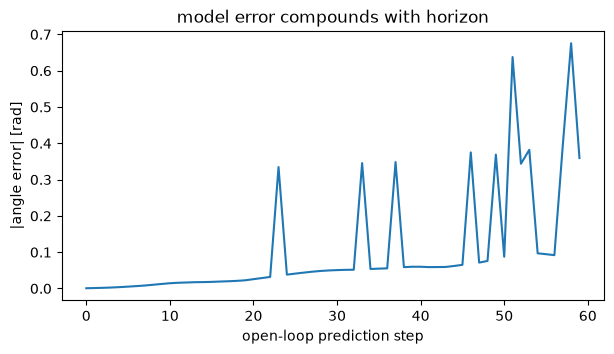

In [3]:
env = PendulumEnv(); errs = []
with torch.no_grad():
    for e in range(20):
        o, _ = env.reset(seed=500 + e); x = torch.tensor(o)[None]; rng = np.random.default_rng(e); err = []
        for t in range(60):
            u = rng.uniform(-1, 1, 1); o, *_ = env.step(u); x = model(x, torch.tensor(u, dtype=torch.float32)[None])
            err.append(float(np.abs(np.arctan2(o[1], o[0]) - torch.atan2(x[0, 1], x[0, 0]).item())))
        errs.append(err)
plt.figure(figsize=(7, 3.5)); plt.plot(np.mean(errs, 0)); plt.xlabel("open-loop prediction step"); plt.ylabel("|angle error| [rad]"); plt.title("model error compounds with horizon"); plt.show()

planning horizon  2: return   -1651  (0s)


planning horizon  5: return   -1684  (0s)


planning horizon 10: return   -1120  (1s)


planning horizon 20: return    -237  (1s)


planning horizon 40: return    -218  (2s)


planning horizon 60: return    -338  (3s)


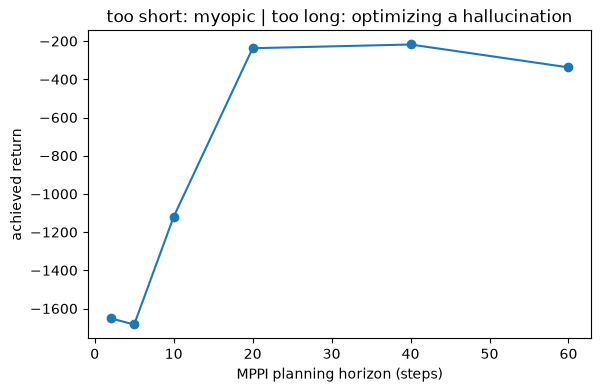

In [4]:
horizons = [2, 5, 10, 20, 40, 60]
rets = []
for H in horizons:
    t0 = time.time(); r = np.mean([mppi_episode(model, H, seed=s) for s in range(3)]); rets.append(r)
    print(f"planning horizon {H:2d}: return {r:7.0f}  ({time.time() - t0:.0f}s)")
plt.figure(figsize=(6.5, 4)); plt.plot(horizons, rets, "o-"); plt.xlabel("MPPI planning horizon (steps)"); plt.ylabel("achieved return")
plt.title("too short: myopic | too long: optimizing a hallucination"); plt.show()